# 08: Clusters, not pairs: deuterium in a palladium vacancy

Every calculation so far used one isolated pair. Under heavy loading, palladium forms **superabundant vacancies** (Fukai), and a vacancy can trap up to ~6 hydrogen atoms. LENR proposals (e.g. Takahashi's tetrahedral condensate) invoke such clusters to bring deuterons closer than the lattice allows. This notebook asks:

1. **Geometry:** how close do N = 2–6 deuterons sit when they share one vacancy?
2. **Rate:** what fusion rate does the closest pair in a cluster have, with and without the measured screening?
3. **What a cluster would need:** what spacing gives watts for a lattice-type pair, and what energy does it cost to hold a pair there?

**Model (rough, stated):** N deuterons, each bound to a trap shell at radius r_t from the vacancy centre (harmonic, PdD phonon stiffness), with Thomas–Fermi-screened mutual repulsion. Classical minimum-energy geometry, then the closest pair's quantum relative motion from the validated solver. Not a DFT or path-integral calculation: it locates orders of magnitude.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import optimize
from cfsolve import *
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#0b0b0b","#52514e"
LAM = 0.574/BOHR_A                                   # Thomas-Fermi length, bohr
K_SITE = MD_ME*(37e-3/HARTREE_EV)**2                 # site force constant from the PdD phonon
LOG_WATT, LOG_LIMIT = np.log10(5.6e-11), np.log10(2e-26)

## 1. Geometry of N deuterons in one vacancy

In [2]:
def cluster(N, r_t_A, seed=0):
    r_t = r_t_A/BOHR_A
    def E(x):
        P = x.reshape(N, 3); e = 0.5*K_SITE*np.sum((np.linalg.norm(P, axis=1) - r_t)**2)
        for i in range(N):
            for j in range(i+1, N):
                d = np.linalg.norm(P[i] - P[j]); e += np.exp(-d/LAM)/d
        return e
    best = None
    rng = np.random.default_rng(seed)
    for _ in range(12):
        x0 = rng.normal(size=(N, 3)); x0 = (x0/np.linalg.norm(x0, axis=1)[:, None]*r_t).ravel()
        r = optimize.minimize(E, x0, method="BFGS")
        if best is None or r.fun < best.fun: best = r
    P = best.x.reshape(N, 3)
    d = [np.linalg.norm(P[i]-P[j]) for i in range(N) for j in range(i+1, N)]
    return min(d)*BOHR_A, np.mean(np.linalg.norm(P, axis=1))*BOHR_A, best.fun*HARTREE_EV
print("trap radius r_t (A): DFT-type values for H at a Pd vacancy are roughly 1.5–1.9 A; smaller values are hypothetical")
geo = {}
for r_t in [1.9, 1.6, 1.2, 0.8]:
    for N in [2, 3, 4, 6]:
        nn, rr, e = cluster(N, r_t); geo[(r_t, N)] = nn
        print(f"r_t = {r_t:.1f} A, N = {N}: closest D-D {nn:.3f} A (shell radius {rr:.3f} A), cluster energy {e:6.2f} eV")

trap radius r_t (A): DFT-type values for H at a Pd vacancy are roughly 1.5–1.9 A; smaller values are hypothetical
r_t = 1.9 A, N = 2: closest D-D 3.829 A (shell radius 1.915 A), cluster energy   0.00 eV


r_t = 1.9 A, N = 3: closest D-D 3.396 A (shell radius 1.961 A), cluster energy   0.04 eV


r_t = 1.9 A, N = 4: closest D-D 3.281 A (shell radius 2.010 A), cluster energy   0.10 eV


r_t = 1.9 A, N = 6: closest D-D 3.011 A (shell radius 2.130 A), cluster energy   0.41 eV
r_t = 1.6 A, N = 2: closest D-D 3.288 A (shell radius 1.644 A), cluster energy   0.02 eV


r_t = 1.6 A, N = 3: closest D-D 3.010 A (shell radius 1.738 A), cluster energy   0.09 eV


...

r_t = 1.2 A, N = 4: closest D-D 2.650 A (shell radius 1.623 A), cluster energy   0.56 eV


r_t = 1.2 A, N = 6: closest D-D 2.563 A (shell radius 1.813 A), cluster energy   1.54 eV
r_t = 0.8 A, N = 2: closest D-D 2.319 A (shell radius 1.160 A), cluster energy   0.19 eV


r_t = 0.8 A, N = 3: closest D-D 2.363 A (shell radius 1.364 A), cluster energy   0.61 eV


r_t = 0.8 A, N = 4: closest D-D 2.430 A (shell radius 1.488 A), cluster energy   1.14 eV


r_t = 0.8 A, N = 6: closest D-D 2.395 A (shell radius 1.694 A), cluster energy   2.73 eV


## 2. Fusion rate of the closest pair in a cluster

In [3]:
def pair_rate(d0_A):
    return solve(V_lattice(d0_A=d0_A), d0_A/BOHR_A + 7.0, Rmin_well=0.4*d0_A/BOHR_A)["log10_rate"]
print("bare (no extra screening):")
for (r_t, N), nn in geo.items():
    if N in (2, 6):
        print(f"   r_t = {r_t:.1f} A, N = {N}: closest pair {nn:.3f} A -> rate 10^{pair_rate(nn):.1f} /s")
print(f"\nreference: lattice pair at 2.75 A -> 10^{pair_rate(2.75):.1f} /s")

bare (no extra screening):


   r_t = 1.9 A, N = 2: closest pair 3.829 A -> rate 10^-142.2 /s


   r_t = 1.9 A, N = 6: closest pair 3.011 A -> rate 10^-127.4 /s


   r_t = 1.6 A, N = 2: closest pair 3.288 A -> rate 10^-131.8 /s


   r_t = 1.6 A, N = 6: closest pair 2.788 A -> rate 10^-124.4 /s


   r_t = 1.2 A, N = 2: closest pair 2.706 A -> rate 10^-123.4 /s


   r_t = 1.2 A, N = 6: closest pair 2.563 A -> rate 10^-121.7 /s


   r_t = 0.8 A, N = 2: closest pair 2.319 A -> rate 10^-119.2 /s


   r_t = 0.8 A, N = 6: closest pair 2.395 A -> rate 10^-120.0 /s



reference: lattice pair at 2.75 A -> 10^-123.9 /s


**Holding a pair at a chosen spacing.** A lattice-strength spring can't hold two deuterons at picometre spacing against their repulsion. So model a hypothetical confinement that supplies exactly the inward force needed at spacing $d_0$ (a linear term), plus a curvature equal to the PdD phonon or 100× stiffer. The work that force does is the energy any real mechanism would have to provide.

In [4]:
def held_rate(d0_A, stiff=1.0):
    d0 = d0_A/BOHR_A; K = stiff*MU_DD*(37e-3/HARTREE_EV)**2
    c = np.exp(-d0/LAM)*(1/d0**2 + 1/(LAM*d0))           # inward force that cancels the repulsion at d0
    V = lambda R: np.exp(-R/LAM)/R + 0.5*K*(R - d0)**2 + c*(R - d0)
    return solve(V, d0 + 7.0/np.sqrt(stiff), r0=min(1e-5, d0*1e-3), Rmin_well=0.3*d0)["log10_rate"]
d0s = np.logspace(np.log10(0.03), np.log10(2.75), 45)
held = {st: np.array([held_rate(d, st) for d in d0s]) for st in [1.0, 100.0]}
def spacing_at(lr, t):
    return 10**np.interp(t, lr[::-1], np.log10(d0s)[::-1]) if (lr.max() > t > lr.min()) else np.nan
def coulomb_eV(d_A): return 14.3996*np.exp(-d_A/0.574)/d_A
for st, lr in held.items():
    dw, dl = spacing_at(lr, LOG_WATT), spacing_at(lr, LOG_LIMIT)
    print(f"curvature x{st:g}: 1 W/cm^3 needs pair held at {dw*100:5.1f} pm; null-limit rate at {dl*100:5.1f} pm")
dw = spacing_at(held[1.0], LOG_WATT); dl = spacing_at(held[1.0], LOG_LIMIT)
for d in [dl, dw]:
    cost = coulomb_eV(d) - coulomb_eV(2.75)
    print(f"   energy to hold a pair at {d*100:5.1f} pm against screened repulsion: {cost:6.0f} eV "
          f"-> Boltzmann factor at 300 K: 10^{-cost/(8.617e-5*300)/np.log(10):.0f}")
print("   (for comparison: D absorption enthalpy in Pd ~0.1–0.2 eV per atom; vacancy-trap binding ~0.2–0.3 eV)")

curvature x1: 1 W/cm^3 needs pair held at   7.3 pm; null-limit rate at  18.1 pm
curvature x100: 1 W/cm^3 needs pair held at   7.3 pm; null-limit rate at  18.1 pm
   energy to hold a pair at  18.1 pm against screened repulsion:     58 eV -> Boltzmann factor at 300 K: 10^-975
   energy to hold a pair at   7.3 pm against screened repulsion:    174 eV -> Boltzmann factor at 300 K: 10^-2918
   (for comparison: D absorption enthalpy in Pd ~0.1–0.2 eV per atom; vacancy-trap binding ~0.2–0.3 eV)


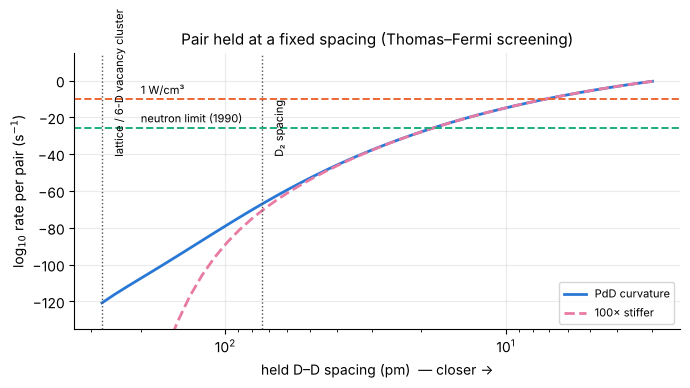

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.9))
ax.plot(d0s*100, held[1.0], color=BLUE, lw=2, label="PdD curvature")
ax.plot(d0s*100, held[100.0], color=MAGENTA, lw=2, ls="--", label="100× stiffer")
ax.legend(fontsize=8, loc="lower right")
for y, lab, col in [(LOG_WATT, "1 W/cm³", ORANGE), (LOG_LIMIT, "neutron limit (1990)", AQUA)]:
    ax.axhline(y, color=col, ls="--", lw=1.4); ax.text(200, y+3, lab, fontsize=8)
for x, lab in [(275, "lattice / 6-D vacancy cluster"), (74, "D₂ spacing")]:
    ax.axvline(x, color=MUTED, ls=":", lw=1); ax.text(x*0.92, -40, lab, rotation=90, fontsize=8, ha="left")
ax.set_xscale("log"); ax.invert_xaxis(); ax.set_ylim(-135, 15)
ax.set_xlabel("held D–D spacing (pm)  — closer →"); ax.set_ylabel("log$_{10}$ rate per pair (s$^{-1}$)")
ax.set_title("Pair held at a fixed spacing (Thomas–Fermi screening)")
plt.tight_layout(); plt.savefig("../figures/08_held_spacing.png", dpi=130); plt.show()

## 3. Clusters plus the measured screening

Repeat notebook 04's beam-consistent band (exponential profile) for the closest pair of a 6-deuteron vacancy cluster.

In [6]:
NU0 = 37e-3/4.135667e-15
ELLS = np.logspace(np.log10(0.01), np.log10(0.4), 32)
def band(d0_A, U):
    Vb = V_lattice(d0_A=d0_A); d0 = d0_A/BOHR_A; Rmax = d0 + 7.0; Rmin = 0.4*d0
    E_lat = solve(Vb, Rmax, Rmin_well=Rmin)["E"]; out = []
    for ell in ELLS:
        ex = extra_screening(beam_matched_dU(U, ell), ell); V = lambda R: Vb(R) + ex(R)
        try: out.append(solve(V, Rmax, Rmin_well=Rmin)["log10_rate"])
        except Collapse:
            B = solve(V, Rmax, Rmin_well=1e-4); r = np.logspace(-4, np.log10(Rmax), 200000); v = V(r)
            imin = np.argmin(np.where(r < Rmin, v, np.inf)); sel = (r > r[imin]) & (r < d0) & (v > E_lat)
            G = 2*np.trapezoid(np.sqrt(2*MU_DD*np.clip(v[sel]-E_lat, 0, None)), r[sel])
            out.append(min(np.log10(NU0) - G/np.log(10), B["log10_rate"]))
    return np.array(out)
nn6 = geo[(1.6, 6)]
for U in [300, 575, 800]:
    a, b = band(2.75, U), band(nn6, U)
    f = lambda e, t: f"{ELLS[np.where(e > t)[0][0]]:.3f} A" if np.any(e > t) else "never"
    print(f"U_meas = {U} eV: lattice pair max 10^{a.max():.1f} (null crossed at {f(a, LOG_LIMIT)}); "
          f"6-D cluster pair ({nn6:.2f} A) max 10^{b.max():.1f} (null at {f(b, LOG_LIMIT)}, watts at {f(b, LOG_WATT)})")

U_meas = 300 eV: lattice pair max 10^-17.9 (null crossed at 0.154 A); 6-D cluster pair (2.79 A) max 10^-17.9 (null at 0.174 A, watts at never)


U_meas = 575 eV: lattice pair max 10^-11.3 (null crossed at 0.137 A); 6-D cluster pair (2.79 A) max 10^-11.3 (null at 0.137 A, watts at never)


U_meas = 800 eV: lattice pair max 10^-8.7 (null crossed at 0.137 A); 6-D cluster pair (2.79 A) max 10^-8.7 (null at 0.137 A, watts at 0.174 A)


## 4. Verdict

* **Clusters don't bring deuterons closer; in this model they push them apart.** With DFT-like trap radii (1.6–1.9 Å), the closest D–D distance in a vacancy cluster is **2.8–3.8 Å**, at or beyond the bulk 2.75 Å, because mutual repulsion pushes cluster members outward. Even a hypothetical 0.8 Å trap radius only reaches ~2.3–2.4 Å. Bare pair rates stay at 10⁻¹¹⁹ to 10⁻¹⁴² s⁻¹.
* **The required spacing is tiny and expensive.** Held by an external force with lattice-like curvature, a pair needs **7.3 pm** for watts, matching the 7–8 pm found independently for molecules in notebook 06. The curvature of the hold doesn't matter (100× stiffer gives the same 7.3 pm). Holding a pair at 7.3 pm costs **~170 eV**, and even at the neutron-limit spacing (18 pm) ~60 eV: ~10²–10³ times the binding energies the lattice offers (Boltzmann factors 10⁻⁹⁷⁵ and 10⁻²⁹¹⁸). The Boltzmann factor makes it impossible at equilibrium, consistent with Leggett & Baym's equilibrium bound.
* **With measured screening, clusters change the range bound only slightly:** the null-limit crossing moves by ≲0.02 Å and the maximum rate is unchanged (compare the lattice and cluster numbers above). Past the cliff, the physics is set at sub-ångström separations, so the starting geometry matters little. That agrees with notebook 04's finding that the lattice details barely matter.
* **Many-body correlations beyond this model** (quantum exchange in a condensate, Takahashi-type symmetric collapse) would need to overcome the same ~100-eV-scale energy cost per pair. Notebook 07 shows they can't dispose of the resulting fusion energy as heat anyway.

**Model limits:** classical geometry plus harmonic pair motion; no DFT; spherical vacancy shell; Thomas–Fermi screening; trap radii from typical DFT literature values (not re-verified).